# 05 - Tuning the Top 2 Models + Benchmark with Variance
**Goal:** (1) tune only the best 2 models (depth over breadth), (2) report **mean +/- standard deviation over 3 different random splits** instead of one lucky number, (3) translate the best model into a business decision.

*Top 2 models in notebook 04 should be Logistic Regression and the Calibrated SVM - the first code cell checks this.*

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]
RAW = Path("../data/raw")
PROC = Path("../data/processed")     # cleaned text + feature matrices made in notebook 02
MODELS = Path("../models")
ASSETS = Path("../assets")
for folder in (PROC, MODELS, ASSETS):
    folder.mkdir(exist_ok=True)

import re
import scipy.sparse as sp
from sklearn.model_selection import train_test_split
from sklearn.pipeline import FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import MultinomialNB
import gc
from sklearn.metrics import roc_auc_score, f1_score


def evaluate(y_true, probs):
    """Returns (column-averaged ROC-AUC, macro F1 at 0.5, list of per-label AUCs)."""
    y_true = np.asarray(y_true)
    aucs = []
    for i in range(6):
        if y_true[:, i].sum() == 0:          # label missing in this split -> cannot compute AUC
            aucs.append(np.nan)
        else:
            aucs.append(roc_auc_score(y_true[:, i], probs[:, i]))
    f1 = f1_score(y_true, (probs >= 0.5).astype(int), average="macro", zero_division=0)
    return np.nanmean(aucs), f1, aucs


def to_matrix(proba_list):
    """Tree / KNN models give a list of (n,2) arrays (one per label) -> one (n,6) matrix."""
    return np.column_stack([p[:, 1] if p.shape[1] == 2 else np.zeros(len(p)) for p in proba_list])

comparison = pd.read_csv(PROC / "results_04.csv")
top2 = comparison["Model"].head(2).tolist()
print("Top 2 from notebook 04:", top2)
if not all(("Logistic" in m or "SVM" in m) for m in top2):
    print("WARNING: the top 2 are not LR/SVM. This notebook only tunes LR and SVM - revisit this choice.")

Top 2 from notebook 04: ['Logistic Regression', 'Calibrated Linear SVM']


## 1. Tuning
To keep the validation set clean, tuning uses **only the training data**: we take 40,000 training comments, split them 75/25 into `tune-train` and `tune-dev`, and compare settings on `tune-dev`.

* Logistic Regression: `C` (inverse regularisation; small C = stronger regularisation)
* Calibrated SVM: `C` (margin softness)

In [2]:
# load the saved training matrix, keep only 40,000 random rows, then free the big matrix (saves memory)
X_train_full = sp.load_npz(PROC / "X_train_tfidf.npz")
y_train_full = pd.read_csv(PROC / "y_train.csv")[LABELS].values

rng = np.random.RandomState(0)
perm = rng.permutation(X_train_full.shape[0])[:40000]
X_sub, y_sub = X_train_full[perm], y_train_full[perm]
del X_train_full
gc.collect()

cut = int(0.75 * len(perm))
X_tt, y_tt = X_sub[:cut], y_sub[:cut]
X_td, y_td = X_sub[cut:], y_sub[cut:]
print("tune-train:", X_tt.shape[0], "| tune-dev:", X_td.shape[0])

tune_rows = []
for c in [0.5, 1.0, 4.0, 10.0]:
    m = OneVsRestClassifier(LogisticRegression(C=c, max_iter=1000)).fit(X_tt, y_tt)
    tune_rows.append({"Model": "Logistic Regression", "C": c, "dev ROC-AUC": evaluate(y_td, m.predict_proba(X_td))[0]})
    print("LR  C =", c, "->", round(tune_rows[-1]["dev ROC-AUC"], 4))

for c in [0.1, 0.5, 1.0]:
    m = OneVsRestClassifier(CalibratedClassifierCV(LinearSVC(C=c), cv=3)).fit(X_tt, y_tt)
    tune_rows.append({"Model": "Calibrated SVM", "C": c, "dev ROC-AUC": evaluate(y_td, m.predict_proba(X_td))[0]})
    print("SVM C =", c, "->", round(tune_rows[-1]["dev ROC-AUC"], 4))

tune_df = pd.DataFrame(tune_rows)
best_lr_c = tune_df[tune_df["Model"] == "Logistic Regression"].sort_values("dev ROC-AUC").iloc[-1]["C"]
best_svm_c = tune_df[tune_df["Model"] == "Calibrated SVM"].sort_values("dev ROC-AUC").iloc[-1]["C"]
print("\nChosen -> LR C =", best_lr_c, "| SVM C =", best_svm_c)
tune_df.round(4)

tune-train: 30000 | tune-dev: 10000


LR  C = 0.5 -> 0.9752


LR  C = 1.0 -> 0.978


LR  C = 4.0 -> 0.9784


LR  C = 10.0 -> 0.9747


SVM C = 0.1 -> 0.9799


SVM C = 0.5 -> 0.9744


SVM C = 1.0 -> 0.9711

Chosen -> LR C = 4.0 | SVM C = 0.1


,Model,C,dev ROC-AUC
0,Logistic Regression,0.5,0.9752
1,Logistic Regression,1.0,0.9780
2,Logistic Regression,4.0,0.9784
3,Logistic Regression,10.0,0.9747
4,Calibrated SVM,0.1,0.9799
5,Calibrated SVM,0.5,0.9744
6,Calibrated SVM,1.0,0.9711


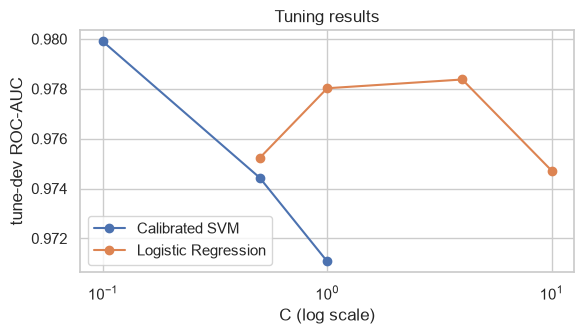

7594

In [3]:
plt.figure(figsize=(6, 3.5))
for name, grp in tune_df.groupby("Model"):
    plt.plot(grp["C"], grp["dev ROC-AUC"], marker="o", label=name)
plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("tune-dev ROC-AUC")
plt.title("Tuning results")
plt.legend()
plt.tight_layout()
plt.savefig(ASSETS / "tuning_curves.png", dpi=150)
plt.show()

del X_tt, X_td, X_sub      # free memory
gc.collect()

## 2. Benchmark: 3 random splits, mean +/- std
For every seed we **re-split the whole dataset, re-fit the vectorizer on the new training part only** (no leakage), train the models and score them. Models: tuned Logistic Regression, tuned Calibrated SVM, Naive Bayes.

> Decision Tree, KNN and Random Forest were clearly behind in notebook 04 and are expensive to repeat (they need the SVD step each time), so they are **not** repeated 3 times; their single-run numbers from 04 are listed for reference at the end.

This cell takes a while on the full dataset (about 7-8 minutes per seed on a laptop).

In [4]:
def load_all_text():
    t = pd.concat([pd.read_csv(PROC / "train_clean.csv"), pd.read_csv(PROC / "val_clean.csv")], ignore_index=True)
    t["clean_text"] = t["clean_text"].fillna("")
    return t

SEEDS = [42, 7, 2024]
records = []
first_seed_probs = {}     # keep probabilities of the first seed for the business analysis

for seed in SEEDS:
    print(f"\n=== seed {seed} ===")
    all_text = load_all_text()                 # re-read each time so memory is freed between seeds
    tr, va = train_test_split(all_text, test_size=0.2, random_state=seed, stratify=all_text["toxic"])
    ytr, yva = tr[LABELS].values, va[LABELS].values
    del all_text

    union = FeatureUnion([
        ("word", TfidfVectorizer(analyzer="word", ngram_range=(1, 2), max_features=10000, sublinear_tf=True)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), max_features=20000, sublinear_tf=True)),
    ])
    Xtr = union.fit_transform(tr["clean_text"])
    Xva = union.transform(va["clean_text"])
    del tr, va, union                          # the text is not needed any more -> free memory
    gc.collect()

    models = {
        f"Logistic Regression (C={best_lr_c})": OneVsRestClassifier(LogisticRegression(C=best_lr_c, max_iter=1000)),
        f"Calibrated SVM (C={best_svm_c})": OneVsRestClassifier(CalibratedClassifierCV(LinearSVC(C=best_svm_c), cv=3)),
        "Naive Bayes (alpha=0.1)": OneVsRestClassifier(MultinomialNB(alpha=0.1)),
    }
    for name, model in models.items():
        start = time.time()
        model.fit(Xtr, ytr)
        probs = model.predict_proba(Xva)
        auc, f1, _ = evaluate(yva, probs)
        records.append({"Model": name, "seed": seed, "ROC-AUC": auc, "Macro F1": f1,
                        "Train time (s)": time.time() - start})
        print(f"  {name}: AUC {auc:.4f} | F1 {f1:.4f}")
        if seed == SEEDS[0]:
            first_seed_probs[name] = probs
    if seed == SEEDS[0]:
        first_seed_y = yva
    del Xtr, Xva, models
    gc.collect()


=== seed 42 ===


  Logistic Regression (C=4.0): AUC 0.9827 | F1 0.6001


  Calibrated SVM (C=0.1): AUC 0.9845 | F1 0.6033


  Naive Bayes (alpha=0.1): AUC 0.9632 | F1 0.4554

=== seed 7 ===


  Logistic Regression (C=4.0): AUC 0.9835 | F1 0.5790


  Calibrated SVM (C=0.1): AUC 0.9858 | F1 0.6025


  Naive Bayes (alpha=0.1): AUC 0.9640 | F1 0.4552

=== seed 2024 ===


  Logistic Regression (C=4.0): AUC 0.9853 | F1 0.5938


  Calibrated SVM (C=0.1): AUC 0.9867 | F1 0.5984


  Naive Bayes (alpha=0.1): AUC 0.9668 | F1 0.4561


In [5]:
bench = pd.DataFrame(records)
summary = bench.groupby("Model").agg(
    auc_mean=("ROC-AUC", "mean"), auc_std=("ROC-AUC", "std"),
    f1_mean=("Macro F1", "mean"), f1_std=("Macro F1", "std"),
    time_mean=("Train time (s)", "mean")).sort_values("auc_mean", ascending=False)

final_table = pd.DataFrame({
    "ROC-AUC (mean +/- std)": [f"{r.auc_mean:.4f} +/- {r.auc_std:.4f}" for r in summary.itertuples()],
    "Macro F1 (mean +/- std)": [f"{r.f1_mean:.4f} +/- {r.f1_std:.4f}" for r in summary.itertuples()],
    "Train time (s)": summary["time_mean"].round(0).values,
}, index=summary.index)
final_table.to_csv(PROC / "benchmark_final.csv")
display(final_table)
display(bench.round(4))

,ROC-AUC (mean +/- std),Macro F1 (mean +/- std),Train time (s)
Model,,,
Calibrated SVM (C=0.1),0.9856 +/- 0.0011,0.6014 +/- 0.0026,106.0
Logistic Regression (C=4.0),0.9838 +/- 0.0013,0.5910 +/- 0.0108,71.0
Naive Bayes (alpha=0.1),0.9646 +/- 0.0019,0.4556 +/- 0.0004,5.0


,Model,seed,ROC-AUC,Macro F1,Train time (s)
0,Logistic Regression (C=4.0),42,0.9827,0.6001,79.8261
1,Calibrated SVM (C=0.1),42,0.9845,0.6033,116.4754
2,Naive Bayes (alpha=0.1),42,0.9632,0.4554,5.4832
3,Logistic Regression (C=4.0),7,0.9835,0.5790,62.8568
4,Calibrated SVM (C=0.1),7,0.9858,0.6025,100.2589
5,Naive Bayes (alpha=0.1),7,0.9640,0.4552,5.5808
6,Logistic Regression (C=4.0),2024,0.9853,0.5938,70.8172
7,Calibrated SVM (C=0.1),2024,0.9867,0.5984,100.1177
8,Naive Bayes (alpha=0.1),2024,0.9668,0.4561,4.8415


**Single-run reference numbers (notebook 04, seed 42) for the models not repeated:**

In [6]:
ref = comparison[~comparison["Model"].str.contains("Logistic|SVM|Naive")][["Model", "ROC-AUC", "Macro F1"]]
ref.round(4)

,Model,ROC-AUC,Macro F1
3,Random Forest (40 trees),0.9310,0.2798
4,"KNN (k=31, 40k subset)",0.8812,0.3092
5,Decision Tree (depth=4),0.8715,0.2224


## 3. Compare with the published benchmark
* The Kaggle competition winner scored **0.9885** mean column-wise ROC-AUC on the (hidden) private test set. A simple Logistic Regression baseline on Kaggle was reported around **0.976** on the public leaderboard (see `PROPOSAL.md` for the sources).
* Our numbers are measured on a **validation split of train.csv**, not on Kaggle's hidden test set, so the comparison is only rough.

In [7]:
BENCHMARK_WINNER = 0.9885
best_name = summary.index[0]
best_auc = summary.iloc[0]["auc_mean"]
print(f"Best model: {best_name}")
print(f"Our mean ROC-AUC: {best_auc:.4f}  vs  Kaggle winner: {BENCHMARK_WINNER}  -> gap = {BENCHMARK_WINNER - best_auc:+.4f}")

Best model: Calibrated SVM (C=0.1)
Our mean ROC-AUC: 0.9856  vs  Kaggle winner: 0.9885  -> gap = +0.0029


### Honest reflection (what to write in the report)
* **What helped:** tuning `C` made the SVM overtake Logistic Regression (a smaller `C`, i.e. stronger regularisation, worked best), and a leakage-free split keeps the numbers honest. The word-only vs hybrid ablation is in the capstone notebook (Section 7).
* **What is the gap?** The Kaggle winners used big ensembles of deep neural networks with pretrained embeddings (e.g. GloVe/FastText), augmentation and pseudo-labelling; our project deliberately stays with fast, explainable linear models and skips the neural-network stage. The gap number printed above is the honest distance.
* **Where we are weak:** rare labels (`threat`, `identity_hate`). Their AUC is lower and noisier than the common labels.

## 4. From metrics to a business decision
We now apply the 3-tier moderation rule to the best model's predictions on the first split:
* **PUBLISH** if max probability < 0.40
* **REVIEW** if between 0.40 and 0.75 (human moderator)
* **REMOVE** if max probability > 0.75, or `threat` / `severe_toxic` > 0.60

In [8]:
best_probs = first_seed_probs[[m for m in first_seed_probs if best_name.split(" (")[0] in m][0]]
y_true = first_seed_y

max_p = best_probs.max(axis=1)
critical = (best_probs[:, LABELS.index("threat")] > 0.60) | (best_probs[:, LABELS.index("severe_toxic")] > 0.60)
decision = np.where((max_p > 0.75) | critical, "REMOVE", np.where(max_p >= 0.40, "REVIEW", "PUBLISH"))

is_toxic = y_true.sum(axis=1) > 0
table = pd.DataFrame({
    "PUBLISH": [(decision[is_toxic] == "PUBLISH").sum(), (decision[~is_toxic] == "PUBLISH").sum()],
    "REVIEW":  [(decision[is_toxic] == "REVIEW").sum(),  (decision[~is_toxic] == "REVIEW").sum()],
    "REMOVE":  [(decision[is_toxic] == "REMOVE").sum(),  (decision[~is_toxic] == "REMOVE").sum()],
}, index=["Actually toxic", "Actually clean"])
display(table)

caught = (decision[is_toxic] != "PUBLISH").mean() * 100
auto_removed_toxic = (decision[is_toxic] == "REMOVE").mean() * 100
wrongly_removed = (decision[~is_toxic] == "REMOVE").mean() * 100
review_share = (decision == "REVIEW").mean() * 100
print(f"Toxic comments that did NOT go live (removed or reviewed): {caught:.1f}%")
print(f"Toxic comments removed automatically                      : {auto_removed_toxic:.1f}%")
print(f"Clean comments wrongly removed (unfair censorship)        : {wrongly_removed:.2f}%")
print(f"Share of ALL comments a human moderator must look at      : {review_share:.1f}%")

,PUBLISH,REVIEW,REMOVE
Actually toxic,805,464,1967
Actually clean,28388,222,69


Toxic comments that did NOT go live (removed or reviewed): 75.1%
Toxic comments removed automatically                      : 60.8%
Clean comments wrongly removed (unfair censorship)        : 0.24%
Share of ALL comments a human moderator must look at      : 2.1%


**Business sentence for the report:** with this setup the platform stops most toxic comments before they go live, wrongly removes only a very small share of clean comments, and needs human moderators to read just the "REVIEW" share of all comments instead of everything (numbers are printed above).

Next: `06_clustering.ipynb` (K-Means and Hierarchical clustering of toxic comments).